Setup stuff

In [76]:
import numpy as np
import pandas as pd
import bambi as bmb
import arviz as az

In [77]:
df = pd.read_csv("domestic_well_radon.csv")
df = df.dropna(subset=["log_radon", "well_depth_ft", "lithology", "aquifer"])
df["log_depth"] = np.log(df["well_depth_ft"])
df["centered_log_depth"] = (df["log_depth"] - df["log_depth"].mean())
df = df[["log_radon", "centered_log_depth", "lithology", "aquifer"]]
df.dropna()
print("Number of lithologies:", df["lithology"].nunique())
print("Number of aquifers:", df["aquifer"].nunique())
print("Wells with complete data:", len(df))
print(df.groupby("lithology")["log_radon"].agg(["count", "mean", "std", "min", "max"]))
df.head()

Number of lithologies: 9
Number of aquifers: 42
Wells with complete data: 2077
                                                    count      mean       std  \
lithology                                                                       
Basalt and other volcanic-rock aquifers                15  5.507268  1.458491   
Carbonate-rock                                        200  5.713703  1.171247   
Crystalline-rock                                      282  7.601792  1.301691   
Glacial                                               311  5.723762  0.902455   
Sandstone                                             276  6.592041  1.085284   
Sandstone and carbonate-rock                           41  5.933747  0.764686   
Semi-consolidated sand                                234  5.423905  0.825127   
Unconsolidated sand and gravel (non-glacial)          689  6.233652  0.677248   
Unconsolidated sand and gravel (non-glacial) an...     29  5.724681  0.480025   

                             

,log_radon,centered_log_depth,lithology,aquifer
0,5.950643,-1.004532,Unconsolidated sand and gravel (non-glacial),Surficial
1,5.880533,-0.229892,Unconsolidated sand and gravel (non-glacial),Surficial
2,6.865891,-0.880480,Unconsolidated sand and gravel (non-glacial),Surficial
3,7.259820,-1.103623,Unconsolidated sand and gravel (non-glacial),Surficial
4,7.028201,-1.062801,Unconsolidated sand and gravel (non-glacial),Surficial


Priors (change later):

In [80]:
aquifer_hierarchical_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0),
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0))
}
combined_hierarchical_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0),
    "1|lithology": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0))
}

combined_varying_sigma_hierarchical_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "1|lithology": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    "sigma": {
        "lithology": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    },
}
lithology_specific_depth_coefficient_priors = { "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0), 
    "centered_log_depth|lithology": bmb.Prior(
        "Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=0.5)
    ),
    "1|lithology": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0))
}       
pooled_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0),
}

Model. Hierarchical, with intercept from lithology & aquifer

In [81]:
combined_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
    ),
    data=df,
    priors=combined_hierarchical_priors,
)

combined_varying_sigma_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
        "sigma ~ 0 + lithology",
    ),
    data=df,
    priors=combined_varying_sigma_hierarchical_priors,
)

aquifer_hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | aquifer)",
    ),
    data=df,
    priors=aquifer_hierarchical_priors,
)

lithology_specific_depth_coefficient_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (centered_log_depth | lithology) + (1 | lithology) + (1 | aquifer)",
    ),
    data=df,
    priors=lithology_specific_depth_coefficient_priors,
)

pooled_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth",
    ),
    data=df,
    priors=pooled_priors,
)

In [82]:
combined_hierarchical_fit = combined_hierarchical_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 47 seconds.


In [83]:
combined_varying_sigma_hierarchical_fit = combined_varying_sigma_hierarchical_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset, sigma_lithology]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 72 seconds.


In [56]:
aquifer_hierarchical_fit =  aquifer_hierarchical_model.fit(target_accept=0.8, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|aquifer_sigma, 1|aquifer_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 8 seconds.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [84]:
lithology_specific_depth_coefficient_fit =  lithology_specific_depth_coefficient_model.fit(target_accep=0.95, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, centered_log_depth|lithology_sigma, centered_log_depth|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 37 seconds.
There were 3 divergences after tuning. Increase `target_accept` or reparameterize.


In [58]:
pooled_fit =  pooled_model.fit(target_accept=0.8, idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Summary statistics:

=== combined_hierarchical ===
Divergences: 0
                     mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  \
Intercept           6.097  0.292   5.537    6.621      0.008    0.006   
centered_log_depth -0.113  0.034  -0.177   -0.048      0.000    0.001   
sigma               0.890  0.014   0.863    0.916      0.000    0.000   
1|lithology_sigma   0.790  0.238   0.401    1.232      0.006    0.005   
1|aquifer_sigma     0.457  0.075   0.322    0.600      0.002    0.001   

                    ess_bulk  ess_tail  r_hat  
Intercept             1397.0    1616.0    1.0  
centered_log_depth    5089.0    2943.0    1.0  
sigma                 5292.0    2459.0    1.0  
1|lithology_sigma     1517.0    2082.0    1.0  
1|aquifer_sigma       1110.0    1913.0    1.0  
LOO: combined_hierarchical
Computed from 4000 posterior samples and 2077 observations log-likelihood matrix.

         Estimate       SE
elpd_loo -2724.01    45.27
p_loo       37.20        -
------

Pareto k diagnostic values:
 

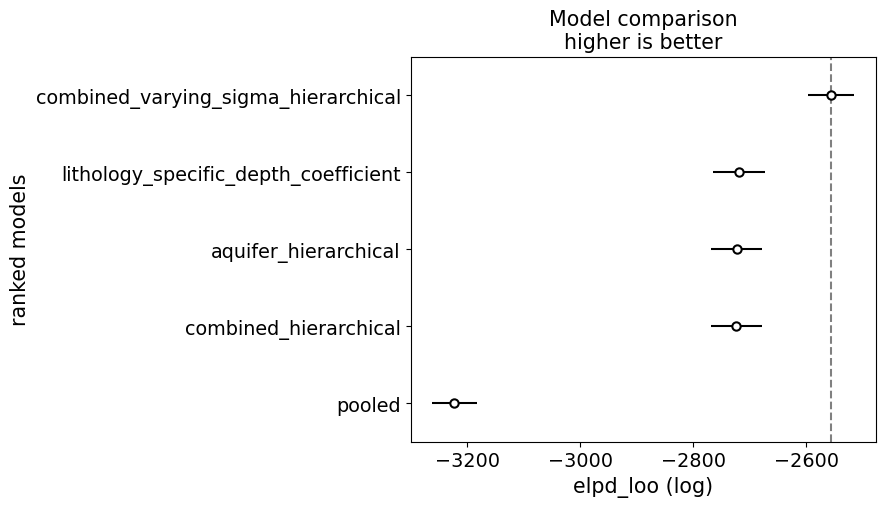

In [85]:
import arviz as az

def analyze_fit(name, fit, var_names):
    print(f"=== {name} ===")
    print("Divergences:", int(fit.sample_stats["diverging"].sum()))
    print(az.summary(fit, var_names=var_names))

    loo = az.loo(fit, pointwise=True)
    print(f"LOO: {name}")
    print(loo)
    print()
    return loo


def compare_models(fits):
    print("=== Model comparison ===")
    comparison = az.compare(fits)
    print(comparison)
    az.plot_compare(comparison)
    return comparison



common_vars = ["Intercept", "centered_log_depth", "sigma"]

models = {
    "combined_hierarchical": (
        combined_hierarchical_fit,
        common_vars + ["1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "combined_varying_sigma_hierarchical": (
        combined_varying_sigma_hierarchical_fit,
        ["Intercept", "centered_log_depth", "sigma_lithology", "1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "aquifer_hierarchical": (
        aquifer_hierarchical_fit,
        common_vars + ["1|aquifer_sigma"],
    ),
    "lithology_specific_depth_coefficient": (
        lithology_specific_depth_coefficient_fit,
        common_vars + ["centered_log_depth|lithology_sigma", "1|lithology_sigma", "1|aquifer_sigma"],
    ),
    "pooled": (
        pooled_fit,
        common_vars,
    ),
}

loos = {name: analyze_fit(name, fit, var_names) for name, (fit, var_names) in models.items()}

comparison = compare_models({name: fit for name, (fit, _) in models.items()})
